#**<font color="00E5FF"> Implementación y comparación de algoritmos de Clustering**</font>

**<font color="BDC3C7">Código de segmentación no supervisada: K-Means · DBSCAN · Clustering Jerárquico**

---



- **<font color="BDC3C7">Elaborado por:** </font>Brayan Yesid Vega Niño
- **<font color="BDC3C7">Fecha:** </font>4 de noviembre de 2026
- **<font color="BDC3C7">Curso:** </font>CADI - Introducción a Machine Learning
- **<font color="BDC3C7">Caso:** </font>Ejercicios propuestos de Clustering (Semana 11) con los datasets *Wine*, *Make Moons* e *Iris* de Scikit-learn.
- **<font color="BDC3C7">Algoritmos:** </font>K-Means (Wine) · DBSCAN (Make Moons) · Clustering Jerárquico Aglomerativo (Iris).


##**<font color="BB86FC">Contenido** </n> <font color=#FFFFFF>


- Sección 0 · Preparación del entorno de trabajo
- Sección 1 · Ejercicio 1: K-Means (Wine)
- Sección 2 · Ejercicio 2: DBSCAN (Make Moons)
- Sección 3 · Ejercicio 3: Clustering Jerárquico (Iris)
- Sección 4 · Comparación de los algoritmos
- Sección 5 · Conclusiones
- Sección 6 · Referencias

---

---
<a id="seccion-0"></a>
##**<font color="BB86FC">Sección 0 · Preparación del entorno de trabajo**

**<font color="2ECC71">Preparación de entorno:</font>** Se cargan las librerías, se fija la **semilla global** (`SEED = 42`) para que los resultados sean reproducibles y se definen las carpetas donde el cuaderno guarda las figuras (`/figures`) y los datos de ejemplo (`/data`). Las versiones de las librerías están en `requirements.txt`.

---

In [1]:
# Librerías base
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Opciones de visualización
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# Reproducibilidad: una única semilla para todo el cuaderno
SEED = 42
np.random.seed(SEED)

# Carpetas de salida: el cuaderno vive en /notebooks; figuras y datos en la raíz del repositorio
BASE = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
FIG_DIR = os.path.join(BASE, "figures")
DATA_DIR = os.path.join(BASE, "data")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# Paleta fija para identificar los clusters en todas las gráficas
COLORES = ["teal", "salmon", "#8064A2", "goldenrod", "skyblue", "seagreen", "tomato", "slategray"]

### <font color="2ECC71">0.1 Funciones comunes (métricas, etiquetado y gráficas)

>**<font color="BDC3C7">Nota:</font>** Se reutilizan en los tres ejercicios. `metricas_internas` calcula **Silhouette, Davies-Bouldin y Calinski-Harabasz** y permite decidir **cómo tratar el ruido (-1)** de DBSCAN. `reordenar_etiquetas` numera los clusters con un criterio fijo (p. ej. de mayor a menor contenido medio de una variable), de modo que el etiquetado sea **estable entre ejecuciones y versiones de Scikit-learn**.

In [2]:
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

def metricas_internas(X, etiquetas, ignorar_ruido=True):
    """Calcula las tres métricas internas de validación de clustering.

    Parámetros
    ----------
    X : array (n, d)
        Datos con los que se construyeron los clusters (ya preprocesados).
    etiquetas : array (n,)
        Etiqueta de cluster de cada observación. El valor -1 es ruido (DBSCAN).
    ignorar_ruido : bool
        True  -> se excluyen los puntos -1 antes de calcular las métricas.
        False -> el ruido se trata como un cluster más (penaliza el resultado).

    Devuelve
    --------
    dict con Silhouette (mayor es mejor), Davies-Bouldin (menor es mejor) y
    Calinski-Harabasz (mayor es mejor). Si no hay al menos 2 clusters válidos,
    las métricas no están definidas y se devuelve NaN.
    """
    etiquetas = np.asarray(etiquetas)
    if ignorar_ruido:
        validos = etiquetas != -1
        X, etiquetas = X[validos], etiquetas[validos]
    n_clusters = len(np.unique(etiquetas))
    if n_clusters < 2 or n_clusters > len(etiquetas) - 1:
        return {"Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    return {
        "Silhouette": silhouette_score(X, etiquetas),
        "Davies-Bouldin": davies_bouldin_score(X, etiquetas),
        "Calinski-Harabasz": calinski_harabasz_score(X, etiquetas),
    }


def reordenar_etiquetas(etiquetas, criterio, ascendente=False):
    """Renumera los clusters 0..k-1 ordenándolos por la media de `criterio`.

    Los algoritmos asignan números de cluster arbitrarios; con esta función el
    cluster 0 es siempre el de mayor (o menor) media de `criterio`.
    """
    etiquetas = np.asarray(etiquetas)
    medias = pd.Series(np.asarray(criterio)).groupby(etiquetas).mean().sort_values(ascending=ascendente)
    mapa = {antiguo: nuevo for nuevo, antiguo in enumerate(medias.index)}
    return np.array([mapa[e] for e in etiquetas])


def guardar_figura(nombre):
    """Guarda la figura activa en /figures (PNG, 200 dpi) para usarla en el informe."""
    plt.savefig(os.path.join(FIG_DIR, nombre + ".png"), dpi=200, bbox_inches="tight")

---
<a id="seccion-1"></a>
##**<font color="BB86FC">Sección 1 · Ejercicio 1: K-Means (Wine)**

**<font color="2ECC71">Objetivo:</font>** Segmentar muestras de vino a partir de su composición físico-química con **K-Means**, elegir el número de clusters con el método del codo y el Silhouette Score, validar el modelo con tres métricas internas e interpretar los grupos con las variables originales. **La variable `target` no se usa para construir los clusters.**

---

### <font color="2ECC71">1.1 Carga del dataset y descripción general (actividades 1 y 2)

>**<font color="BDC3C7">Nota:</font>** Se separa explícitamente `X_wine` (las 13 variables predictoras, única entrada de los algoritmos) de `y_wine` (clase de cultivar), que se conserva **solo como referencia posterior**.

In [3]:
from sklearn.datasets import load_wine

data_wine = load_wine(as_frame=True)
X_wine = data_wine.data.copy()     # 13 variables físico-químicas: única entrada de K-Means
y_wine = data_wine.target.copy()   # cultivar real: NO se usa para agrupar, solo para comparar al final

print("Registros y variables:", X_wine.shape)
print("\nTipos de datos:")
print(X_wine.dtypes.value_counts().to_string())
print("\nVariables:", list(X_wine.columns))
print("\nDistribución de la clase real (solo referencia):")
print(y_wine.value_counts().sort_index().to_string())

# Dato de ejemplo para el repositorio
pd.concat([X_wine, y_wine.rename("target")], axis=1).to_csv(os.path.join(DATA_DIR, "wine.csv"), index=False)
X_wine.head()

Registros y variables: (178, 13)

Tipos de datos:
float64    13

Variables: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Distribución de la clase real (solo referencia):
target
0    59
1    71
2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


**<font color="2ECC71">Interpretación del Ejercicio 1.1:</font>**

- **Tamaño y tipo:** el dataset tiene **178 registros** y **13 variables numéricas continuas** (`float64`): alcohol, ácido málico, ceniza, alcalinidad, magnesio, fenoles totales, flavonoides, fenoles no flavonoides, proantocianinas, intensidad de color, matiz (*hue*), OD280/OD315 y prolina.
- **Etiqueta real:** existen tres cultivares (59, 71 y 48 muestras). Por ser un ejercicio **no supervisado**, se ignora al construir los clusters y solo se usa en la sección 1.9 como contraste opcional.

### <font color="2ECC71">1.2 Revisión de calidad y escala de las variables (actividad 3)

In [4]:
print("Valores nulos en total:", int(X_wine.isna().sum().sum()))

# Estadísticas descriptivas y rango de cada variable
resumen_wine = X_wine.describe().T[["mean", "std", "min", "max"]]
resumen_wine["rango"] = resumen_wine["max"] - resumen_wine["min"]
resumen_wine.round(2)

Valores nulos en total: 0


,mean,std,min,max,rango
alcohol,13.00,0.81,11.03,14.83,3.80
malic_acid,2.34,1.12,0.74,5.80,5.06
ash,2.37,0.27,1.36,3.23,1.87
alcalinity_of_ash,19.49,3.34,10.60,30.00,19.40
magnesium,99.74,14.28,70.00,162.00,92.00
total_phenols,2.30,0.63,0.98,3.88,2.90
flavanoids,2.03,1.00,0.34,5.08,4.74
nonflavanoid_phenols,0.36,0.12,0.13,0.66,0.53
proanthocyanins,1.59,0.57,0.41,3.58,3.17
color_intensity,5.06,2.32,1.28,13.00,11.72


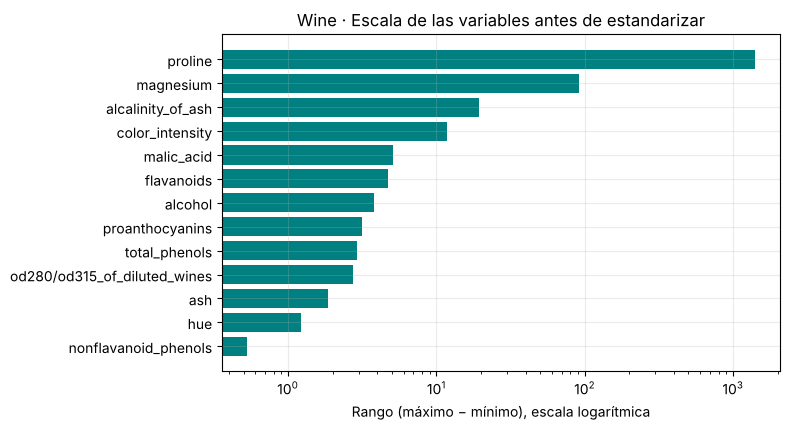

In [5]:
# Escala de las variables ANTES de estandarizar (rango en escala logarítmica)
orden = resumen_wine["rango"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(orden.index, orden.values, color="teal")
ax.set_xscale("log")
ax.set_xlabel("Rango (máximo − mínimo), escala logarítmica")
ax.set_title("Wine · Escala de las variables antes de estandarizar")
plt.tight_layout()
guardar_figura("ej1_escala_variables")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 1.2:</font>**

- **Calidad:** no hay valores nulos, por lo que **no se imputó nada**.
- **Escala:** las variables viven en magnitudes muy distintas. La **prolina** va de 278 a 1.680 (desviación estándar ≈ 315) y el **magnesio** de 70 a 162, mientras que `nonflavanoid_phenols` va de 0,13 a 0,66 (desviación estándar ≈ 0,12). La desviación estándar de la prolina es unas **2.600 veces mayor** que la de los fenoles no flavonoides.

### <font color="2ECC71">1.3 ¿Es necesario estandarizar? (actividad 4)

>**<font color="BDC3C7">Nota:</font>** K-Means decide con **distancia euclidiana**. Si una variable tiene valores de cientos y otra de décimas, la distancia queda determinada casi solo por la primera. Por eso se aplica `StandardScaler` (media 0, desviación 1) antes de agrupar.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler_wine = StandardScaler()
Xs_wine = scaler_wine.fit_transform(X_wine)                       # matriz estandarizada (numpy)
Xs_wine_df = pd.DataFrame(Xs_wine, columns=X_wine.columns)        # misma matriz como DataFrame

print("Máxima media absoluta tras estandarizar:", round(float(np.abs(Xs_wine_df.mean()).max()), 6))
print("Desviación estándar de cada variable   :", Xs_wine_df.std(ddof=0).round(3).unique())

Máxima media absoluta tras estandarizar: 0.0
Desviación estándar de cada variable   : [1.]


**<font color="2ECC71">Interpretación del Ejercicio 1.3:</font>** **Sí era necesario.** Sin estandarizar, la prolina (y en menor medida el magnesio) dominarían el cálculo de distancias y los clusters reflejarían casi únicamente esas variables. Tras estandarizar, las 13 variables tienen media 0 y desviación 1 y aportan de forma comparable. En la sección 1.10 se **demuestra empíricamente** qué pasa si se omite este paso.

### <font color="2ECC71">1.4 K-Means para distintos valores de K (actividades 5 y 6)

>**<font color="BDC3C7">Nota:</font>** Se prueba K = 2 a 10 (el mínimo pedido era 2 a 6; se amplía para ver bien la forma del codo). Para cada K se registra la **inercia** y el **Silhouette Score**; se añaden Davies-Bouldin y Calinski-Harabasz como criterios adicionales. K = 1 solo sirve de referencia para la inercia. Se usa `n_init=10` (10 inicializaciones; se conserva la de menor inercia) y `random_state=42`.

In [7]:
from sklearn.cluster import KMeans

filas = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs_wine)
    fila = {"K": k, "Inercia": km.inertia_}
    if k >= 2:   # las métricas de silueta necesitan al menos 2 clusters
        fila.update(metricas_internas(Xs_wine, km.labels_))
    filas.append(fila)

tabla_k = pd.DataFrame(filas).set_index("K")
tabla_k["Reducción de inercia"] = -tabla_k["Inercia"].diff()   # cuánto baja la inercia al añadir un cluster
tabla_k.round(4)

,Inercia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Reducción de inercia
K,,,,,
1,2314.0000,NaN,NaN,NaN,NaN
2,1658.7589,0.2593,1.5260,69.5233,655.2411
3,1277.9285,0.2849,1.3892,70.9400,380.8304
4,1175.4283,0.2602,1.7969,56.1814,102.5002
5,1109.5127,0.2016,1.8083,46.9522,65.9156
6,1046.0023,0.2372,1.5544,41.7008,63.5104
7,981.5952,0.2036,1.6606,38.6855,64.4071
8,935.2012,0.1570,1.7409,35.8053,46.3940
9,889.8929,0.1499,1.7083,33.8066,45.3083


### <font color="2ECC71">1.5 Método del codo y Silhouette Score (actividad 7)

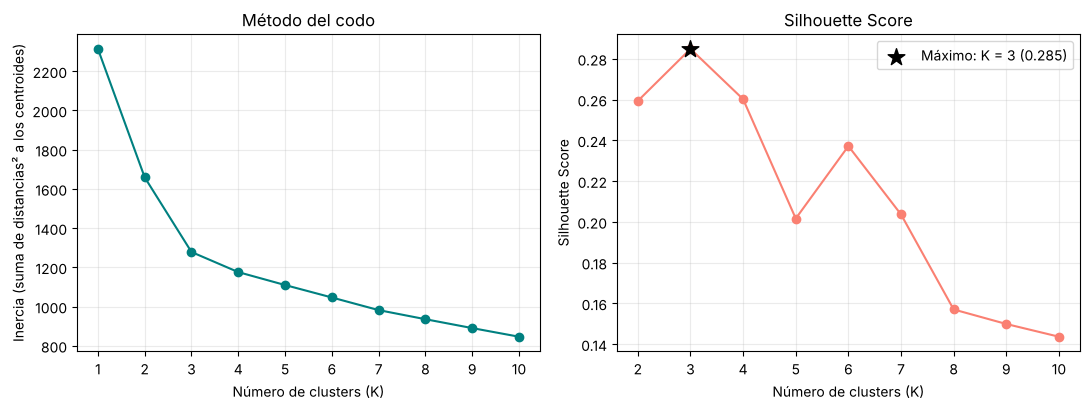

In [8]:
k_sil = int(tabla_k["Silhouette"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Método del codo
axes[0].plot(tabla_k.index, tabla_k["Inercia"], "o-", color="teal")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (K)")
axes[0].set_ylabel("Inercia (suma de distancias² a los centroides)")
axes[0].set_xticks(tabla_k.index)

# Silhouette Score por K
sil = tabla_k["Silhouette"].dropna()
axes[1].plot(sil.index, sil.values, "o-", color="salmon")
axes[1].scatter([k_sil], [sil[k_sil]], s=160, marker="*", color="black", zorder=3,
                label=f"Máximo: K = {k_sil} ({sil[k_sil]:.3f})")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Número de clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(sil.index)
axes[1].legend()

plt.tight_layout()
guardar_figura("ej1_codo_silhouette")
plt.show()

### <font color="2ECC71">1.6 Comparación de criterios y selección de K (actividades 8 y 9)

In [9]:
sub = tabla_k.dropna(subset=["Silhouette"])
print("K con mayor Silhouette        :", int(sub["Silhouette"].idxmax()), "->", round(sub["Silhouette"].max(), 4))
print("K con menor Davies-Bouldin    :", int(sub["Davies-Bouldin"].idxmin()), "->", round(sub["Davies-Bouldin"].min(), 4))
print("K con mayor Calinski-Harabasz :", int(sub["Calinski-Harabasz"].idxmax()), "->", round(sub["Calinski-Harabasz"].max(), 2))
print("\nReducción de inercia al pasar de K-1 a K:")
print(tabla_k["Reducción de inercia"].dropna().round(1).to_string())

K con mayor Silhouette        : 3 -> 0.2849
K con menor Davies-Bouldin    : 3 -> 1.3892
K con mayor Calinski-Harabasz : 3 -> 70.94

Reducción de inercia al pasar de K-1 a K:
K
2     655.2
3     380.8
4     102.5
5      65.9
6      63.5
7      64.4
8      46.4
9      45.3
10     44.0


**<font color="2ECC71">Interpretación del Ejercicio 1.6:</font>**

- **Codo:** la inercia baja mucho al pasar de K=2 a K=3 (**−381**), pero solo −103 al pasar a K=4 y alrededor de −64 en cada paso siguiente. La curva se "quiebra" en **K = 3**.
- **Silhouette:** es máximo en **K = 3 (0,285)**; K=2 (0,259) y K=4 (0,260) quedan por debajo.
- **Criterios adicionales:** Calinski-Harabasz también es máximo en K=3 (70,94) y Davies-Bouldin mínimo en K=3 (1,389).
- **Decisión: K = 3.** El codo, el Silhouette, Davies-Bouldin y Calinski-Harabasz **coinciden**. Además, K=3 es una cantidad razonable de segmentos para interpretar (en la sección 1.9 se contrasta con los tres cultivares reales de forma opcional).

### <font color="2ECC71">1.7 Modelo definitivo de K-Means y métricas (actividades 10 y 11)

>**<font color="BDC3C7">Nota:</font>** Los clusters se renumeran de **mayor a menor contenido medio de prolina** (`reordenar_etiquetas`) para que el etiquetado sea estable. También se comprueba que la solución **no depende de la semilla**.

In [10]:
K_FINAL = 3
km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(Xs_wine)

# Etiquetado estable: cluster 0 = mayor prolina media, cluster 2 = menor
etiq_wine = reordenar_etiquetas(km_final.labels_, X_wine["proline"], ascendente=False)

m_wine = metricas_internas(Xs_wine, etiq_wine)
print("Tamaño de cada cluster:", np.bincount(etiq_wine))
print("Inercia del modelo final:", round(km_final.inertia_, 2))
pd.DataFrame([m_wine], index=["K-Means (K=3)"]).round(4)

Tamaño de cada cluster: [62 51 65]
Inercia del modelo final: 1277.93


,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means (K=3),0.2849,1.3892,70.94


In [11]:
# Robustez: ¿cambia la solución con otra semilla de inicialización?
filas = []
for semilla in [0, 1, 7, 42, 123]:
    km_s = KMeans(n_clusters=K_FINAL, n_init=10, random_state=semilla).fit(Xs_wine)
    filas.append({"Semilla": semilla, "Inercia": km_s.inertia_, "Silhouette": silhouette_score(Xs_wine, km_s.labels_)})
pd.DataFrame(filas).set_index("Semilla").round(4)

,Inercia,Silhouette
Semilla,,
0,1277.9285,0.2849
1,1277.9285,0.2849
7,1277.9285,0.2849
42,1277.9285,0.2849
123,1277.9285,0.2849


**<font color="2ECC71">Interpretación del Ejercicio 1.7:</font>**

- **Métricas del modelo final (K=3):** Silhouette = **0,285**, Davies-Bouldin = **1,389** y Calinski-Harabasz = **70,94**. Los tamaños de los clusters son 62, 51 y 65 muestras (bastante equilibrados).
- **Lectura:** un Silhouette cercano a 0,3 indica una estructura **moderada/débil**: hay grupos reconocibles, pero con solapamiento en las fronteras. Davies-Bouldin > 1 apunta en el mismo sentido (valores más bajos indican grupos más compactos y separados).
- **Estabilidad:** con cinco semillas distintas la inercia (1.277,93) y el Silhouette son idénticos, así que la solución es **estable** (gracias a `n_init=10`).

### <font color="2ECC71">1.8 Visualización 2D con PCA (actividades 12 y 13)

>**<font color="BDC3C7">Nota:</font>** PCA con 2 componentes se usa **únicamente para dibujar**: los clusters ya se construyeron con las 13 variables estandarizadas. Los centroides se proyectan al mismo plano.

Varianza explicada: PC1 = 36.2% | PC2 = 19.2% | total = 55.4%


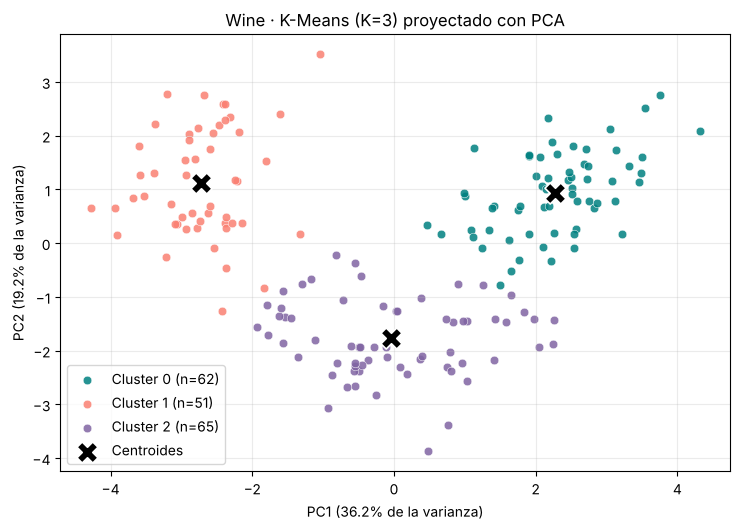

In [12]:
from sklearn.decomposition import PCA

pca_wine = PCA(n_components=2, random_state=SEED)
Z_wine = pca_wine.fit_transform(Xs_wine)
var_wine = pca_wine.explained_variance_ratio_
print(f"Varianza explicada: PC1 = {var_wine[0]:.1%} | PC2 = {var_wine[1]:.1%} | total = {var_wine.sum():.1%}")

# Centroides de cada cluster (en el espacio estandarizado) proyectados a PCA
centroides = pca_wine.transform(Xs_wine_df.groupby(etiq_wine).mean().values)

fig, ax = plt.subplots(figsize=(7.5, 5.4))
for c in range(K_FINAL):
    sel = etiq_wine == c
    ax.scatter(Z_wine[sel, 0], Z_wine[sel, 1], s=38, color=COLORES[c], alpha=0.85,
               edgecolor="white", linewidth=0.4, label=f"Cluster {c} (n={sel.sum()})")
ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=230, color="black",
           edgecolor="white", linewidth=1.2, label="Centroides", zorder=4)
ax.set_xlabel(f"PC1 ({var_wine[0]:.1%} de la varianza)")
ax.set_ylabel(f"PC2 ({var_wine[1]:.1%} de la varianza)")
ax.set_title("Wine · K-Means (K=3) proyectado con PCA")
ax.legend(loc="best")
plt.tight_layout()
guardar_figura("ej1_kmeans_pca")
plt.show()

Observaciones con silueta negativa (posible mala asignación): 7 de 178


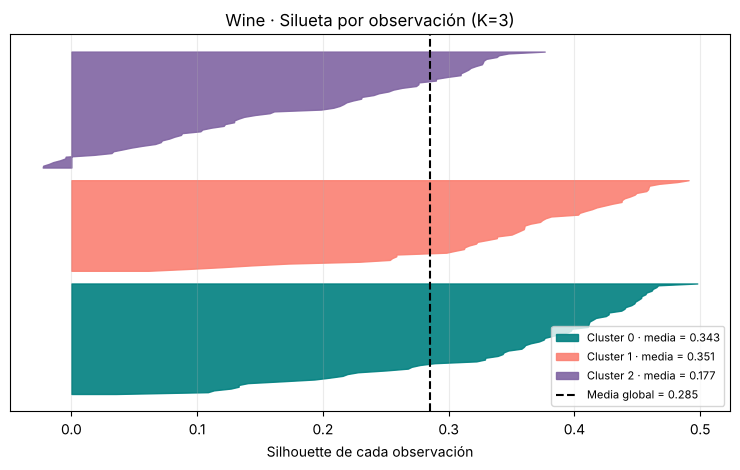

In [13]:
# Calidad de cada cluster: silueta por observación
sil_i = silhouette_samples(Xs_wine, etiq_wine)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
y0 = 0
for c in range(K_FINAL):
    valores = np.sort(sil_i[etiq_wine == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(valores)), 0, valores, color=COLORES[c], alpha=0.9,
                     label=f"Cluster {c} · media = {valores.mean():.3f}")
    y0 += len(valores) + 6
ax.axvline(sil_i.mean(), color="black", ls="--", label=f"Media global = {sil_i.mean():.3f}")
ax.set_xlabel("Silhouette de cada observación")
ax.set_yticks([])
ax.set_title("Wine · Silueta por observación (K=3)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
guardar_figura("ej1_silueta_clusters")
plt.show()

print("Observaciones con silueta negativa (posible mala asignación):", int((sil_i < 0).sum()), "de", len(sil_i))

**<font color="2ECC71">Interpretación del Ejercicio 1.8:</font>**

- **PCA:** los dos primeros componentes explican **36,2 % + 19,2 % = 55,4 %** de la varianza; la gráfica es una **simplificación** (casi la mitad de la información queda fuera del plano), por lo que algunos solapamientos aparentes pueden no existir en las 13 dimensiones.
- **Separación:** el cluster 1 queda a la izquierda (PC1 negativo), el cluster 0 a la derecha y el cluster 2 en la zona inferior (PC2 negativo). Los tres son reconocibles, pero el cluster 2 **roza al cluster 0** y presenta puntos en contacto con ambos vecinos. Por clusters, el Silhouette medio es 0,343 (cluster 0), 0,351 (cluster 1) y **0,177 (cluster 2)**: el cluster 2 es el menos cohesionado y el más cercano a los demás. Solo **7 de 178** observaciones tienen silueta negativa.

### <font color="2ECC71">1.9 Interpretación de los clusters con las variables originales (actividad 14)

>**<font color="BDC3C7">Nota:</font>** Se comparan las **medias en unidades originales** (para describir) y las **medias estandarizadas** (para ver qué variables diferencian más: valores lejos de 0 son características distintivas del grupo). Al final se contrasta, **solo como referencia**, con la clase real.

In [14]:
# Perfil medio de cada cluster en unidades originales
perfil = X_wine.groupby(etiq_wine).mean().T
perfil.columns = [f"Cluster {c}" for c in perfil.columns]
perfil.round(2)

,Cluster 0,Cluster 1,Cluster 2
alcohol,13.68,13.13,12.25
malic_acid,2.00,3.31,1.90
ash,2.47,2.42,2.23
alcalinity_of_ash,17.46,21.24,20.06
magnesium,107.97,98.67,92.74
total_phenols,2.85,1.68,2.25
flavanoids,3.00,0.82,2.05
nonflavanoid_phenols,0.29,0.45,0.36
proanthocyanins,1.92,1.15,1.62
color_intensity,5.45,7.23,2.97


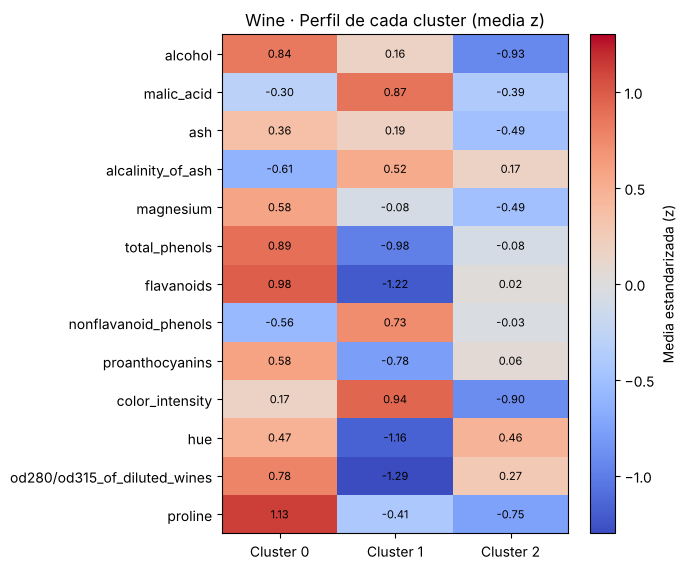

In [15]:
# Mapa de calor: media estandarizada de cada variable por cluster
perfil_z = Xs_wine_df.groupby(etiq_wine).mean().T

fig, ax = plt.subplots(figsize=(6.8, 5.8))
im = ax.imshow(perfil_z.values, cmap="coolwarm", vmin=-1.3, vmax=1.3, aspect="auto")
ax.set_xticks(range(K_FINAL))
ax.set_xticklabels([f"Cluster {c}" for c in range(K_FINAL)])
ax.set_yticks(range(len(perfil_z)))
ax.set_yticklabels(perfil_z.index)
for i in range(perfil_z.shape[0]):
    for j in range(perfil_z.shape[1]):
        ax.text(j, i, f"{perfil_z.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
plt.colorbar(im, label="Media estandarizada (z)")
ax.set_title("Wine · Perfil de cada cluster (media z)")
plt.tight_layout()
guardar_figura("ej1_perfil_clusters")
plt.show()

In [16]:
# Contraste OPCIONAL con la clase real (no se usó para agrupar)
nombres = dict(enumerate(data_wine.target_names))
print("Adjusted Rand Index frente a la clase real:", round(adjusted_rand_score(y_wine, etiq_wine), 3))
pd.crosstab(pd.Series(etiq_wine, name="Cluster"), pd.Series(y_wine.map(nombres), name="Clase real"))

Adjusted Rand Index frente a la clase real: 0.897


Clase real,class_0,class_1,class_2
Cluster,,,
0,59,3,0
1,0,3,48
2,0,65,0


**<font color="2ECC71">Interpretación del Ejercicio 1.9:</font>**

- **Cluster 0 (62 vinos) · "ricos en fenoles y prolina":** el mayor contenido de **prolina (≈1.100)**, flavonoides (3,00), fenoles totales (2,85) y OD280/OD315 (3,16); alcohol alto (13,7) y matiz alto (1,07).
- **Cluster 1 (51 vinos) · "color intenso y bajos fenoles":** la mayor **intensidad de color (7,23)** y **ácido málico (3,31)**, y los valores más bajos de **flavonoides (0,82)**, OD280/OD315 (1,70), fenoles totales (1,68) y matiz (0,69).
- **Cluster 2 (65 vinos) · "suaves, bajo alcohol":** el menor **alcohol (12,25)**, la menor intensidad de color (2,97) y la menor prolina (≈510); flavonoides intermedios (2,05).
- **Contraste con la clase real (opcional):** los clusters reproducen casi exactamente los tres cultivares (**172 de 178** muestras coinciden; ARI = 0,897). Solo 6 muestras de la clase 1 quedan en el cluster 0 o en el 1. Esto confirma que la estructura encontrada tiene sentido, pero **la etiqueta no intervino en la construcción**.

### <font color="2ECC71">1.10 Efecto de no estandarizar (limitación metodológica)

>**<font color="BDC3C7">Nota:</font>** Se repite K-Means con K=3 sobre los datos **sin escalar** para comprobar el argumento de la sección 1.3.

In [17]:
km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine)
et_raw = km_raw.labels_

comparacion_escala = pd.DataFrame({
    "Silhouette (calculado en su propio espacio)": [silhouette_score(Xs_wine, etiq_wine), silhouette_score(X_wine, et_raw)],
    "ARI frente a la clase real (ref.)": [adjusted_rand_score(y_wine, etiq_wine), adjusted_rand_score(y_wine, et_raw)],
    "Tamaños de los clusters": [str(sorted(int(t) for t in np.bincount(etiq_wine))), str(sorted(int(t) for t in np.bincount(et_raw)))],
}, index=["Con StandardScaler", "Sin escalar"])
comparacion_escala.round(3)

,Silhouette (calculado en su propio espacio),ARI frente a la clase real (ref.),Tamaños de los clusters
Con StandardScaler,0.285,0.897,"[51, 62, 65]"
Sin escalar,0.571,0.371,"[47, 62, 69]"


**<font color="2ECC71">Interpretación del Ejercicio 1.10:</font>** Sin escalar, el Silhouette **sube a 0,571** (parece mejor), pero el acuerdo con la clase real **cae de 0,897 a 0,371**: los clusters quedan determinados casi solo por la prolina, que domina la distancia. Es un buen ejemplo de que **una métrica interna alta no garantiza clusters útiles** si el preprocesamiento es inadecuado.

---

### <font color="2ECC71">1.11 Preguntas de análisis del Ejercicio 1

>**<font color="BDC3C7">1. ¿Qué valor de K considera más apropiado?:</font>**
**K = 3.** Es el máximo del Silhouette (0,285), de Calinski-Harabasz (70,94) y el mínimo de Davies-Bouldin (1,389), y coincide con el codo de la inercia.

>**<font color="BDC3C7">2. ¿El Método del Codo y Silhouette sugieren el mismo resultado?:</font>**
**Sí, ambos apuntan a K = 3.** El codo es un criterio visual (la inercia siempre baja al aumentar K) y en este caso es nítido: la reducción cae de −381 a −103. Aun así, K=2 queda muy cerca en Calinski-Harabasz (69,5 frente a 70,9), por lo que la ventaja de K=3 es real pero moderada.

>**<font color="BDC3C7">3. ¿Qué indica la inercia?:</font>**
La **suma de las distancias al cuadrado** entre cada observación y el centroide de su cluster: mide la **cohesión interna** (menor = grupos más compactos). Con K=3 es 1.277,9 frente a 2.314,0 con K=1, es decir, el agrupamiento elimina ≈ 44,8 % de la dispersión total. Por sí sola no sirve para elegir K porque **siempre disminuye** al añadir clusters (llegaría a 0 con K = n).

>**<font color="BDC3C7">4. ¿Los clusters obtenidos presentan una separación clara?:</font>**
**Parcialmente.** Los tres grupos se distinguen en el plano PCA, pero el Silhouette (0,285) y Davies-Bouldin (1,389) indican estructura moderada con solapamiento en las fronteras. El cluster 2 es el más débil (Silhouette medio 0,177) y 7 observaciones tienen silueta negativa.

>**<font color="BDC3C7">5. ¿Qué características permiten diferenciar los grupos?:</font>**
**Flavonoides, fenoles totales, OD280/OD315, matiz, prolina, intensidad de color y alcohol.** Por ejemplo, el cluster 0 combina flavonoides y prolina altos; el cluster 1, color intenso con flavonoides bajos; y el cluster 2, bajo alcohol y poca intensidad de color.

>**<font color="BDC3C7">6. ¿Qué limitaciones identifica en el resultado obtenido?:</font>**
(a) K-Means asume clusters **convexos y de tamaño/varianza parecidos** y requiere fijar K. (b) Es **sensible a la escala**: sin estandarizar el resultado se degrada (sección 1.10). (c) La estructura es moderada (Silhouette ≈ 0,29). (d) La visualización PCA solo conserva el 55,4 % de la varianza. (e) El agrupamiento depende de la distancia euclidiana en 13 dimensiones, donde las distancias pierden contraste. (f) Con 178 muestras, el resultado puede cambiar con otra muestra de vinos.

---

<a id="seccion-2"></a>
##**<font color="BB86FC">Sección 2 · Ejercicio 2: DBSCAN (Make Moons)**

**<font color="2ECC71">Objetivo:</font>** Aplicar **DBSCAN** a un conjunto con forma de dos lunas, explorar el efecto de `eps` y `min_samples`, identificar el **ruido** y evaluar la solución con métricas internas tratando correctamente los puntos etiquetados como -1.

---

### <font color="2ECC71">2.1 Generación y visualización de los datos (actividades 1 y 2)

>**<font color="BDC3C7">Nota:</font>** Se generan 500 puntos con `make_moons(n_samples=500, noise=0.07, random_state=42)`. La etiqueta `y_moons` indica a qué luna pertenece cada punto y **no se usa para agrupar**; solo servirá como referencia opcional.

In [18]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=500, noise=0.07, random_state=42)

print("Forma de X_moons:", X_moons.shape)
print("Observaciones por luna (solo referencia):", np.bincount(y_moons))

# Dato de ejemplo para el repositorio
pd.DataFrame(X_moons, columns=["x1", "x2"]).assign(luna=y_moons).to_csv(os.path.join(DATA_DIR, "moons.csv"), index=False)
pd.DataFrame(X_moons, columns=["x1", "x2"]).describe().round(3)

Forma de X_moons: (500, 2)
Observaciones por luna (solo referencia): [250 250]


,x1,x2
count,500.000,500.000
mean,0.506,0.252
std,0.872,0.502
min,-1.132,-0.653
25%,-0.037,-0.210
50%,0.474,0.261
75%,1.058,0.696
max,2.117,1.164


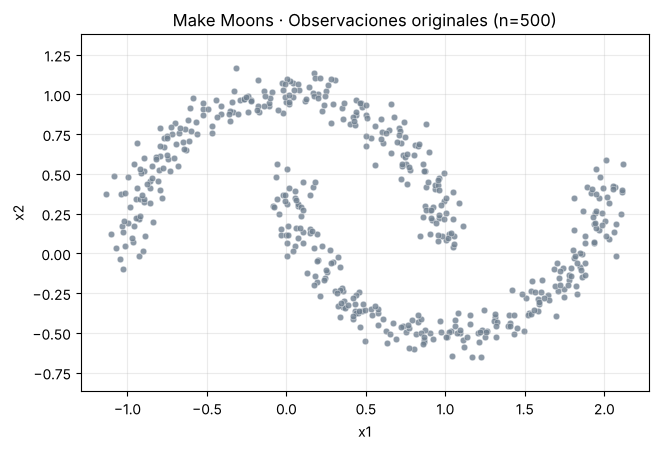

In [19]:
# Datos ANTES de aplicar el algoritmo (sin colorear por etiqueta)
fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.scatter(X_moons[:, 0], X_moons[:, 1], s=22, color="slategray", alpha=0.8, edgecolor="white", linewidth=0.3)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Make Moons · Observaciones originales (n=500)")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
guardar_figura("ej2_datos_originales")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 2.1:</font>** Los datos forman **dos semicírculos entrelazados** (dos "lunas" de 250 puntos cada una) con algo de dispersión alrededor de cada curva (`noise=0.07`). Son grupos **no convexos**: el centro de una luna queda en una zona vacía y más cerca de la otra luna. Es una geometría pensada para que los métodos basados en centroides tengan dificultades y los métodos basados en **densidad** funcionen bien.

### <font color="2ECC71">2.2 Estandarización (actividad 3)

>**<font color="BDC3C7">Nota:</font>** DBSCAN usa distancias, y `eps` se define en las unidades de los datos. Estandarizar hace que `eps` tenga el mismo significado en ambas variables.

In [20]:
from sklearn.preprocessing import StandardScaler

Xs_moons = StandardScaler().fit_transform(X_moons)
print("Media por variable :", Xs_moons.mean(axis=0).round(6))
print("Desv. estándar     :", Xs_moons.std(axis=0).round(3))

Media por variable : [-0. -0.]
Desv. estándar     : [1. 1.]


### <font color="2ECC71">2.3 Elección de eps: gráfico de k-distancias (apoyo a la actividad 5)

>**<font color="BDC3C7">Nota:</font>** Para cada punto se calcula la distancia a su 5.º vecino más cercano (contando el propio punto, igual que `min_samples=5`) y se ordenan de menor a mayor. Un `eps` razonable queda donde la curva empieza a **crecer bruscamente**: por debajo, casi todos los puntos son centrales; por encima, solo los aislados.

Percentil  50: distancia al 5.º vecino = 0.094
Percentil  90: distancia al 5.º vecino = 0.152
Percentil  95: distancia al 5.º vecino = 0.179
Percentil  99: distancia al 5.º vecino = 0.246
Percentil 100: distancia al 5.º vecino = 0.356
Puntos cuyo 5.º vecino queda más lejos que eps=0.2: 16 (3.2 %)
Puntos cuyo 5.º vecino queda más lejos que eps=0.3: 3 (0.6 %)


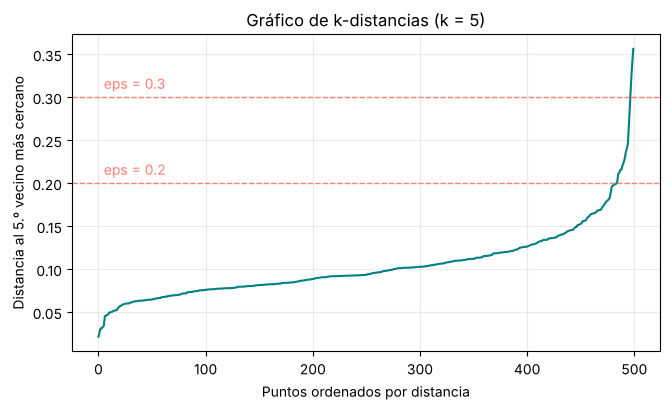

In [21]:
from sklearn.neighbors import NearestNeighbors

MIN_PTS = 5
dist, _ = NearestNeighbors(n_neighbors=MIN_PTS).fit(Xs_moons).kneighbors(Xs_moons)
k_dist = np.sort(dist[:, -1])          # distancia al 5.º vecino (incluye el propio punto)

for p in [50, 90, 95, 99, 100]:
    print(f"Percentil {p:>3}: distancia al {MIN_PTS}.º vecino = {np.percentile(k_dist, p):.3f}")
for e in [0.20, 0.30]:
    print(f"Puntos cuyo {MIN_PTS}.º vecino queda más lejos que eps={e}: {(k_dist > e).sum()} ({100 * (k_dist > e).mean():.1f} %)")

fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.plot(k_dist, color="teal")
for e in [0.2, 0.3]:
    ax.axhline(e, color="salmon", ls="--", lw=1)
    ax.text(5, e + 0.01, f"eps = {e}", color="salmon")
ax.set_xlabel("Puntos ordenados por distancia")
ax.set_ylabel(f"Distancia al {MIN_PTS}.º vecino más cercano")
ax.set_title("Gráfico de k-distancias (k = 5)")
plt.tight_layout()
guardar_figura("ej2_k_distancias")
plt.show()

### <font color="2ECC71">2.4 Experimentos con eps y min_samples (actividades 4, 5 y 6)

>**<font color="BDC3C7">Nota:</font>** Se prueban **12 combinaciones** (el mínimo pedido era 3). Por cada una se registra `eps`, `min_samples`, número de clusters, número y porcentaje de puntos de **ruido** y las tres métricas internas **calculadas sin los puntos de ruido** (solo definidas si hay al menos 2 clusters). Se añade el ARI frente a la etiqueta real únicamente como referencia opcional.

In [22]:
from sklearn.cluster import DBSCAN

configs = [(0.05, 5), (0.10, 5), (0.15, 5), (0.20, 5), (0.25, 5), (0.30, 5),
           (0.40, 5), (0.50, 5), (1.00, 5), (0.30, 3), (0.30, 20), (0.20, 10)]

filas, etiquetas_db = [], {}
for eps, ms in configs:
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs_moons)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)          # el -1 no es un cluster
    n_ruido = int((lab == -1).sum())
    filas.append({
        "eps": eps, "min_samples": ms, "Clusters": n_cl,
        "Ruido (n)": n_ruido, "Ruido (%)": round(100 * n_ruido / len(lab), 1),
        **metricas_internas(Xs_moons, lab, ignorar_ruido=True),
        "ARI (ref.)": adjusted_rand_score(y_moons, lab),
    })
    etiquetas_db[(eps, ms)] = lab

tabla_db = pd.DataFrame(filas)
tabla_db.round(3)

,eps,min_samples,Clusters,Ruido (n),Ruido (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (ref.)
0,0.05,5,4,476,95.2,0.907,0.113,11756.335,0.002
1,0.10,5,24,118,23.6,0.479,0.543,940.051,0.081
2,0.15,5,4,17,3.4,0.143,1.336,232.557,0.755
3,0.20,5,2,4,0.8,0.387,1.018,433.627,0.984
4,0.25,5,2,0,0.0,0.386,1.022,433.882,1.000
5,0.30,5,2,0,0.0,0.386,1.022,433.882,1.000
6,0.40,5,2,0,0.0,0.386,1.022,433.882,1.000
7,0.50,5,1,0,0.0,NaN,NaN,NaN,0.000
8,1.00,5,1,0,0.0,NaN,NaN,NaN,0.000
9,0.30,3,2,0,0.0,0.386,1.022,433.882,1.000


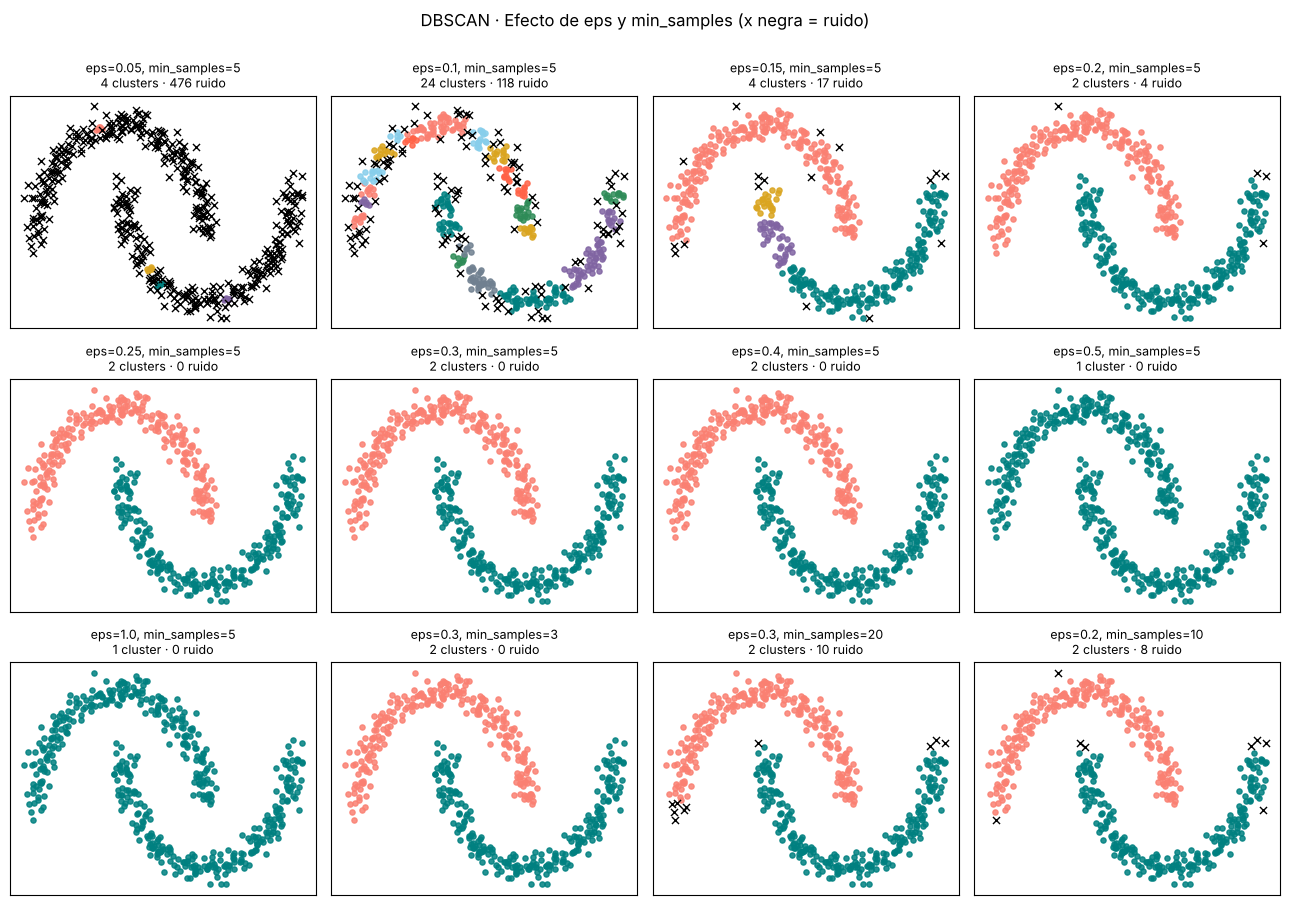

In [23]:
# Panel con todas las configuraciones: clusters en colores, ruido (-1) en negro con "x"
def graficar_dbscan(ax, X, lab, titulo):
    """Dibuja los clusters de DBSCAN; los puntos de ruido (-1) se muestran como 'x' negras."""
    for i, c in enumerate(sorted(set(lab) - {-1})):
        sel = lab == c
        ax.scatter(X[sel, 0], X[sel, 1], s=14, color=COLORES[i % len(COLORES)], alpha=0.85)
    ruido = lab == -1
    if ruido.any():
        ax.scatter(X[ruido, 0], X[ruido, 1], s=26, color="black", marker="x", linewidths=1)
    ax.set_title(titulo, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for ax, (eps, ms) in zip(axes.ravel(), configs):
    lab = etiquetas_db[(eps, ms)]
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    graficar_dbscan(ax, Xs_moons, lab, f"eps={eps}, min_samples={ms}\n{n_cl} {'cluster' if n_cl == 1 else 'clusters'} · {(lab == -1).sum()} ruido")
fig.suptitle("DBSCAN · Efecto de eps y min_samples (x negra = ruido)", y=1.0)
plt.tight_layout()
guardar_figura("ej2_panel_configuraciones")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 2.4:</font>**

- **eps muy pequeño (0,05 y 0,10):** la densidad exigida es demasiado alta. Con 0,05 el **95,2 %** de los puntos queda como ruido (4 micro-clusters); con 0,10 la nube se **fragmenta en 24 clusters** y 23,6 % de ruido.
- **eps intermedio (0,20 a 0,40):** aparece la estructura correcta: **2 clusters**. Con 0,20 y `min_samples=5` hay 4 puntos de ruido (0,8 %); con **0,25, 0,30 y 0,40** (y `min_samples=5`) no hay ruido y los resultados son idénticos (zona de estabilidad).
- **eps grande (0,50 y 1,00):** las dos lunas se **fusionan en un solo cluster** (el puente entre ellas deja de ser un hueco), y las métricas no están definidas.
- **Efecto de `min_samples`:** con `eps=0,30`, subir `min_samples` de 5 a 20 genera 10 puntos de ruido (2,0 %); con `eps=0,20`, subirlo de 5 a 10 duplica el ruido (de 4 a 8). Bajarlo a 3 no cambia nada.
- **Cuidado con las métricas:** la fila `eps=0,05` muestra el Silhouette más alto de la tabla (0,907), pero está calculado solo sobre el 4,8 % de puntos que no son ruido. **Una métrica alta sobre una fracción minúscula de los datos no indica un buen resultado.**

### <font color="2ECC71">2.5 Configuración seleccionada y visualización (actividades 7 y 8)

Clusters encontrados : 2
Tamaño de cada uno   : {0: 250, 1: 250}
Puntos de ruido      : 0


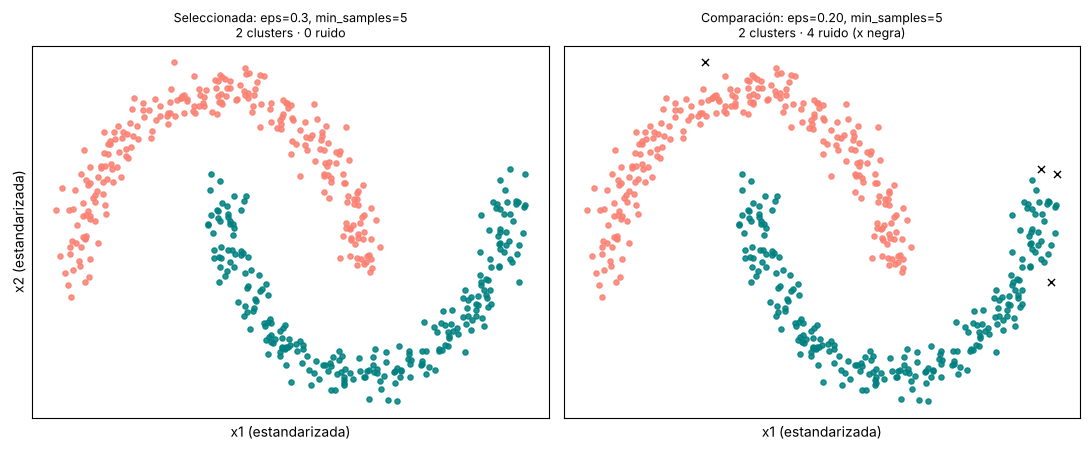

In [24]:
EPS_FINAL, MS_FINAL = 0.30, 5
lab_db = etiquetas_db[(EPS_FINAL, MS_FINAL)]
print("Clusters encontrados :", len(set(lab_db) - {-1}))
print("Tamaño de cada uno   :", {int(c): int((lab_db == c).sum()) for c in sorted(set(lab_db) - {-1})})
print("Puntos de ruido      :", int((lab_db == -1).sum()))

# Elegida (izquierda) frente a una configuración con algo de ruido (derecha)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
graficar_dbscan(axes[0], Xs_moons, lab_db, f"Seleccionada: eps={EPS_FINAL}, min_samples={MS_FINAL}\n2 clusters · 0 ruido")
lab_20 = etiquetas_db[(0.20, 5)]
graficar_dbscan(axes[1], Xs_moons, lab_20, "Comparación: eps=0.20, min_samples=5\n2 clusters · 4 ruido (x negra)")
for ax in axes:
    ax.set_xlabel("x1 (estandarizada)")
axes[0].set_ylabel("x2 (estandarizada)")
plt.tight_layout()
guardar_figura("ej2_dbscan_seleccionada")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 2.5:</font>** Se selecciona **`eps = 0,30` y `min_samples = 5`** por tres razones: (1) produce **2 clusters de 250 puntos** que siguen exactamente la forma de cada luna; (2) está **dentro de la zona estable** (0,25 a 0,40), por lo que no depende de un ajuste fino; y (3) el gráfico de k-distancias muestra que el 99 % de los puntos tiene su 5.º vecino a menos de 0,25 y el máximo es 0,36: con `eps=0,30` **497 de 500 puntos son centrales** y los 3 restantes quedan unidos a un cluster por ser alcanzables desde un punto central. Con `eps=0,20` la solución es casi igual, pero 16 puntos (3,2 %) incumplen la densidad por sí mismos y 4 de ellos terminan como ruido, en los extremos de las lunas.

### <font color="2ECC71">2.6 Métricas y tratamiento del ruido (actividades 9 y 10)

>**<font color="BDC3C7">Nota:</font>** Silhouette, Davies-Bouldin y Calinski-Harabasz **solo están definidos con al menos 2 clusters** y asumen que **todo punto pertenece a un cluster**. El -1 de DBSCAN no es un cluster real, así que hay dos opciones: (a) **excluirlo** del cálculo, o (b) tratarlo **como un cluster más**. Se comparan ambas con `eps=0,20` (que sí tiene ruido); con la configuración seleccionada no hay ruido y ambas opciones coinciden.

In [25]:
filas = {
    "Seleccionada (eps=0.30, ms=5) · sin ruido":      metricas_internas(Xs_moons, lab_db, ignorar_ruido=True),
    "eps=0.20, ms=5 · ruido EXCLUIDO":                metricas_internas(Xs_moons, lab_20, ignorar_ruido=True),
    "eps=0.20, ms=5 · ruido como cluster adicional":  metricas_internas(Xs_moons, lab_20, ignorar_ruido=False),
}
metricas_ruido = pd.DataFrame(filas).T
metricas_ruido.round(4)

,Silhouette,Davies-Bouldin,Calinski-Harabasz
"Seleccionada (eps=0.30, ms=5) · sin ruido",0.3857,1.0215,433.8817
"eps=0.20, ms=5 · ruido EXCLUIDO",0.3869,1.0179,433.6268
"eps=0.20, ms=5 · ruido como cluster adicional",0.2962,1.4257,217.7931


**<font color="2ECC71">Interpretación del Ejercicio 2.6:</font>**

- **Métricas de la configuración seleccionada:** Silhouette = **0,386**, Davies-Bouldin = **1,022** y Calinski-Harabasz = **433,9**.
- **Efecto del ruido:** si los 4 puntos de ruido de `eps=0,20` se tratan como un tercer cluster, el Silhouette baja de 0,387 a 0,296, Davies-Bouldin sube de 1,018 a 1,426 y Calinski-Harabasz cae a la mitad (433,6 → 217,8). Esa penalización **no refleja un peor agrupamiento**, sino que se está tratando como "grupo" algo que no lo es (puntos dispersos sin cohesión).
- **Criterio adoptado:** se **excluyen los puntos -1** para evaluar la calidad de los clusters, **pero siempre se reporta el porcentaje de ruido** (0 % en la configuración seleccionada), porque excluirlo sin informarlo oculta cuánta información se descarta (ver el caso `eps=0,05`).

### <font color="2ECC71">2.7 Contraste con K-Means

>**<font color="BDC3C7">Nota:</font>** Para responder por qué DBSCAN encuentra estructuras difíciles para K-Means, se aplica K-Means con K=2 sobre los mismos datos estandarizados y se comparan las métricas internas (y, como referencia, el ARI).

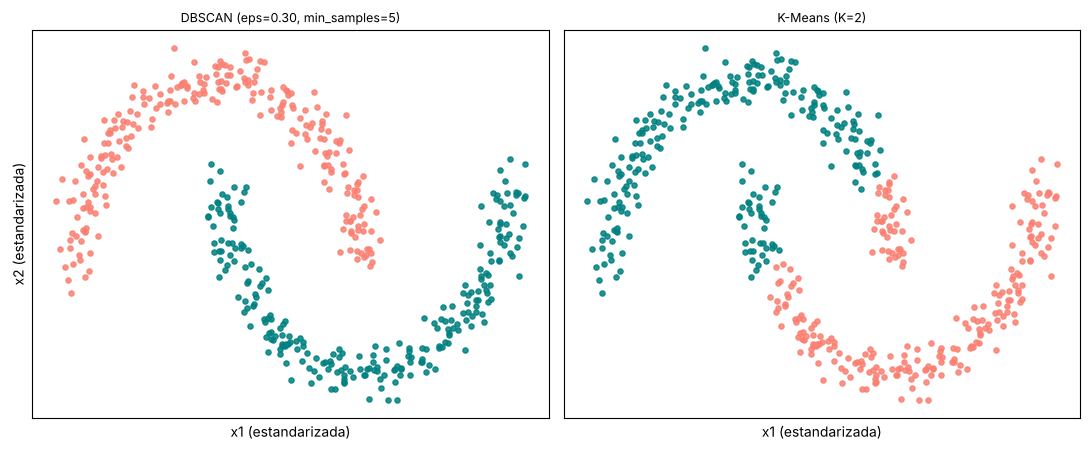

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (ref.)
"DBSCAN (eps=0.30, ms=5)",0.386,1.022,433.882,1.000
K-Means (K=2),0.494,0.812,693.848,0.445


In [26]:
from sklearn.cluster import KMeans

lab_km_moons = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Xs_moons)

comp_moons = pd.DataFrame({
    "DBSCAN (eps=0.30, ms=5)": {**metricas_internas(Xs_moons, lab_db), "ARI (ref.)": adjusted_rand_score(y_moons, lab_db)},
    "K-Means (K=2)":           {**metricas_internas(Xs_moons, lab_km_moons), "ARI (ref.)": adjusted_rand_score(y_moons, lab_km_moons)},
}).T

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
graficar_dbscan(axes[0], Xs_moons, lab_db, "DBSCAN (eps=0.30, min_samples=5)")
graficar_dbscan(axes[1], Xs_moons, lab_km_moons, "K-Means (K=2)")
for ax in axes:
    ax.set_xlabel("x1 (estandarizada)")
axes[0].set_ylabel("x2 (estandarizada)")
plt.tight_layout()
guardar_figura("ej2_dbscan_vs_kmeans")
plt.show()

comp_moons.round(3)

**<font color="2ECC71">Interpretación del Ejercicio 2.7:</font>** K-Means corta las lunas con una **frontera recta** (cada punto va al centroide más cercano) y mezcla partes de las dos lunas; su ARI es 0,445 frente a 1,000 de DBSCAN. Sin embargo, **K-Means obtiene mejores métricas internas** (Silhouette 0,494 frente a 0,386; Davies-Bouldin 0,812 frente a 1,022; Calinski-Harabasz 693,8 frente a 433,9). Las tres métricas premian grupos **compactos y redondeados**, así que **favorecen a K-Means aunque su resultado sea el equivocado**. Con clusters de forma arbitraria, estas métricas deben leerse junto con la gráfica y no como único criterio.

---

### <font color="2ECC71">2.8 Preguntas de análisis del Ejercicio 2

>**<font color="BDC3C7">1. ¿Qué ocurre cuando se disminuye demasiado eps?:</font>**
La vecindad es tan pequeña que casi ningún punto alcanza la densidad mínima: **la mayoría pasa a ser ruido o se forman muchos micro-clusters**. Con `eps=0,05` el 95,2 % de los puntos es ruido y con `eps=0,10` hay 24 clusters fragmentados.

>**<font color="BDC3C7">2. ¿Qué ocurre cuando eps aumenta?:</font>**
Primero se completan los clusters correctos (2 clusters entre 0,20 y 0,40) y el ruido desaparece; si sigue creciendo, **los clusters se fusionan**: con `eps=0,50` las dos lunas forman un solo cluster y con 1,00 también.

>**<font color="BDC3C7">3. ¿Qué función cumple min_samples?:</font>**
Define cuántos vecinos (incluyendo el propio punto) debe haber dentro de `eps` para que un punto sea **central**. Controla la **exigencia de densidad** y la robustez al ruido: valores mayores producen más ruido y clusters más conservadores (con `eps=0,30`, pasar de 5 a 20 genera 10 puntos de ruido).

>**<font color="BDC3C7">4. ¿Qué representan los puntos identificados como ruido?:</font>**
Observaciones en **zonas de baja densidad** que no son alcanzables desde ningún punto central: pueden ser **valores atípicos reales**, puntos de transición o simplemente puntos en los extremos de una estructura. No son un grupo; son una **señal** (posibles anomalías) que hay que revisar.

>**<font color="BDC3C7">5. ¿Qué configuración produjo el resultado más coherente?:</font>**
**`eps = 0,30` y `min_samples = 5`**: 2 clusters de 250 puntos, 0 % de ruido, forma fiel a las lunas y en el centro de la zona estable de `eps`.

>**<font color="BDC3C7">6. ¿Por qué DBSCAN puede encontrar estructuras que podrían resultar difíciles para K-Means?:</font>**
DBSCAN define un cluster como una **región continua de alta densidad**, sin suponer forma; puede seguir curvas. K-Means asigna cada punto al **centroide más cercano**, lo que genera regiones convexas separadas por fronteras rectas y falla con lunas, anillos o formas alargadas (ARI 0,445 frente a 1,000).

>**<font color="BDC3C7">7. ¿Qué ventajas y limitaciones observa en este algoritmo?:</font>**
**Ventajas:** no requiere fijar el número de clusters, detecta formas arbitrarias y **identifica ruido**. **Limitaciones:** es muy sensible a `eps` (el rango útil aquí es acotado: entre 0,25 y 0,40 en las configuraciones probadas, y con 0,50 las lunas ya se fusionan); un único `eps` no sirve cuando los clusters tienen **densidades distintas**; pierde eficacia en **alta dimensión**; las métricas internas habituales penalizan injustamente los clusters no convexos y el ruido complica su cálculo.

---

<a id="seccion-3"></a>
##**<font color="BB86FC">Sección 3 · Ejercicio 3: Clustering Jerárquico (Iris)**

**<font color="2ECC71">Objetivo:</font>** Construir un **dendrograma** con el dataset Iris, analizar las alturas de fusión para proponer un punto de corte, aplicar `AgglomerativeClustering` con el número de clusters elegido y validarlo con tres métricas. **Las etiquetas de especie no se usan para construir los clusters.**

---

### <font color="2ECC71">3.1 Carga del dataset (actividades 1 y 2)

In [27]:
from sklearn.datasets import load_iris

data_iris = load_iris(as_frame=True)
X_iris = data_iris.data.copy()      # 4 medidas de flores: única entrada del algoritmo
y_iris = data_iris.target.copy()    # especie real: NO se usa para agrupar (solo referencia)

print("Registros y variables:", X_iris.shape)
print("Variables:", list(X_iris.columns))
print("Valores nulos:", int(X_iris.isna().sum().sum()))
print("\nDistribución de la especie real (solo referencia):")
print(y_iris.value_counts().sort_index().to_string())

pd.concat([X_iris, y_iris.rename("target")], axis=1).to_csv(os.path.join(DATA_DIR, "iris.csv"), index=False)
X_iris.head()

Registros y variables: (150, 4)
Variables: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Valores nulos: 0

Distribución de la especie real (solo referencia):
target
0    50
1    50
2    50


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**<font color="2ECC71">Interpretación del Ejercicio 3.1:</font>** El dataset tiene **150 observaciones** y **4 variables numéricas continuas** (largo y ancho de sépalo y de pétalo, en cm), sin valores nulos. Hay tres especies con 50 flores cada una; esa información se ignora al agrupar.

### <font color="2ECC71">3.2 Escalas y estandarización (actividad 3)

In [28]:
resumen_iris = X_iris.describe().T[["mean", "std", "min", "max"]]
print(resumen_iris.round(2).to_string())

from sklearn.preprocessing import StandardScaler
Xs_iris = StandardScaler().fit_transform(X_iris)
print("\nMedia tras estandarizar:", Xs_iris.mean(axis=0).round(6))
print("Desv. estándar         :", Xs_iris.std(axis=0).round(3))

                   mean   std  min  max
sepal length (cm)  5.84  0.83  4.3  7.9
sepal width (cm)   3.06  0.44  2.0  4.4
petal length (cm)  3.76  1.77  1.0  6.9
petal width (cm)   1.20  0.76  0.1  2.5

Media tras estandarizar: [-0. -0. -0. -0.]
Desv. estándar         : [1. 1. 1. 1.]


**<font color="2ECC71">Interpretación del Ejercicio 3.2:</font>** Aunque las cuatro variables están en centímetros, su **dispersión es muy distinta**: la desviación estándar del largo del pétalo (1,77) es unas cuatro veces la del ancho del sépalo (0,44). Sin estandarizar, el largo del pétalo pesaría mucho más en las distancias. Se aplica `StandardScaler`.

### <font color="2ECC71">3.3 Dendrograma y análisis de distancias (actividades 4 y 5)

>**<font color="BDC3C7">Nota:</font>** Se usa enlace **Ward** (minimiza el aumento de varianza interna al fusionar) con distancia euclidiana. El eje vertical del dendrograma es la **distancia (altura) a la que se fusionan dos grupos**. Se muestran los últimos 30 grupos para que sea legible.

In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

Z = linkage(Xs_iris, method="ward")                    # matriz de enlace (n-1 fusiones)
coef_cof = cophenet(Z, pdist(Xs_iris))[0]
print(f"Correlación cofenética (fidelidad del dendrograma a las distancias reales): {coef_cof:.3f}")

# Alturas de las últimas fusiones: ¿qué corte deja un salto grande?
filas = []
for k in range(2, 9):
    h_sup = Z[-(k - 1), 2]      # altura de la fusión que reduce de k a k-1 clusters
    h_inf = Z[-k, 2]            # altura de la fusión anterior (de k+1 a k clusters)
    filas.append({"K": k, "Cortar entre (altura)": f"{h_inf:.2f} y {h_sup:.2f}", "Amplitud del intervalo": h_sup - h_inf})
tabla_cortes = pd.DataFrame(filas).set_index("K")
tabla_cortes.round(2)

Correlación cofenética (fidelidad del dendrograma a las distancias reales): 0.823


,Cortar entre (altura),Amplitud del intervalo
K,,
2,12.64 y 27.25,14.61
3,8.00 y 12.64,4.63
4,6.61 y 8.00,1.40
5,4.24 y 6.61,2.36
6,4.23 y 4.24,0.02
7,4.06 y 4.23,0.17
8,3.95 y 4.06,0.11


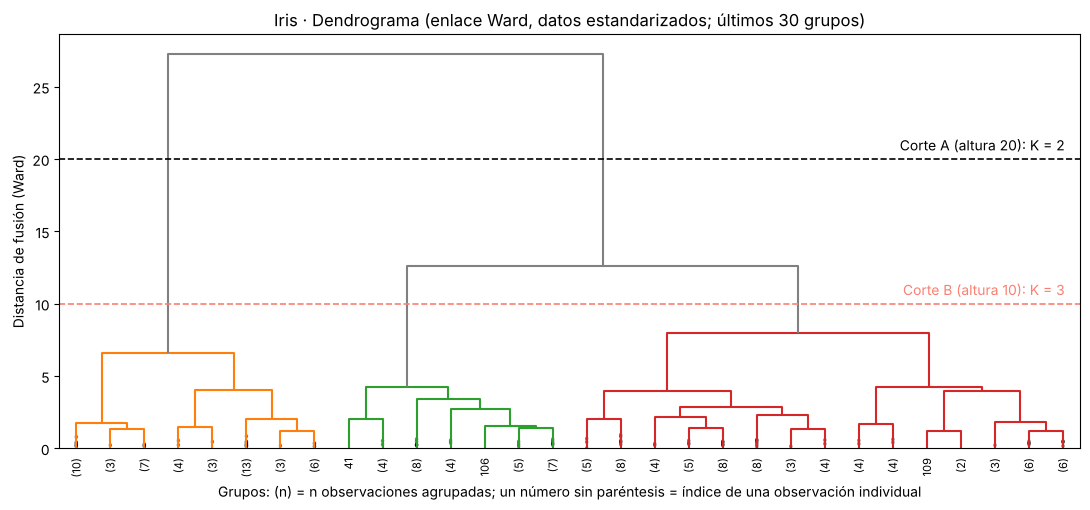

In [30]:
fig, ax = plt.subplots(figsize=(11, 5.2))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
           show_contracted=True, color_threshold=10, above_threshold_color="gray", ax=ax)
ax.axhline(20, color="black", ls="--", lw=1.2)
ax.text(ax.get_xlim()[1] * 0.985, 20.6, "Corte A (altura 20): K = 2", ha="right")
ax.axhline(10, color="salmon", ls="--", lw=1.2)
ax.text(ax.get_xlim()[1] * 0.985, 10.6, "Corte B (altura 10): K = 3", ha="right", color="salmon")
ax.set_title("Iris · Dendrograma (enlace Ward, datos estandarizados; últimos 30 grupos)")
ax.set_xlabel("Grupos: (n) = n observaciones agrupadas; un número sin paréntesis = índice de una observación individual")
ax.set_ylabel("Distancia de fusión (Ward)")
ax.grid(False)
plt.tight_layout()
guardar_figura("ej3_dendrograma")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 3.3:</font>**

- **Fidelidad:** la correlación cofenética es **0,823**: el dendrograma conserva bien las distancias originales entre observaciones.
- **Salto principal:** la última fusión ocurre a una altura de **27,25** y la anterior a **12,64**: un salto de **14,61**, el mayor con diferencia. Cortar en cualquier altura entre 12,64 y 27,25 produce **2 clusters**.
- **Salto secundario:** entre 8,00 y 12,64 hay un segundo salto, mucho menor (4,63), que correspondería a **3 clusters**. Después ningún salto supera 2,36 (K=5) y desde K=6 son casi nulos (0,17 o menos): las fusiones siguientes ocurren casi "al mismo nivel" y no hay evidencia clara de más grupos.

### <font color="2ECC71">3.4 Punto de corte y número de clusters (actividades 6 y 7)

>**<font color="BDC3C7">Nota:</font>** Además del dendrograma, se evalúan K = 2 a 6 con las tres métricas internas para comprobar si respaldan el corte propuesto. El ARI frente a la especie real se incluye **solo como referencia**.

In [31]:
from sklearn.cluster import AgglomerativeClustering

# Comprobación: los dos cortes propuestos producen el número de clusters esperado
for altura in [20, 10]:
    print(f"Corte a altura {altura:>2}: {len(np.unique(fcluster(Z, t=altura, criterion='distance')))} clusters")

filas = []
for k in range(2, 7):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xs_iris)
    filas.append({"K": k, **metricas_internas(Xs_iris, lab), "ARI (ref.)": adjusted_rand_score(y_iris, lab)})
tabla_jer = pd.DataFrame(filas).set_index("K")
tabla_jer.round(4)

Corte a altura 20: 2 clusters
Corte a altura 10: 3 clusters


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (ref.)
K,,,,
2,0.5770,0.5917,240.2457,0.5438
3,0.4467,0.8035,222.7192,0.6153
4,0.4006,0.9788,201.2515,0.5879
5,0.3306,0.9742,192.6813,0.4402
6,0.3149,0.9895,172.1230,0.4214


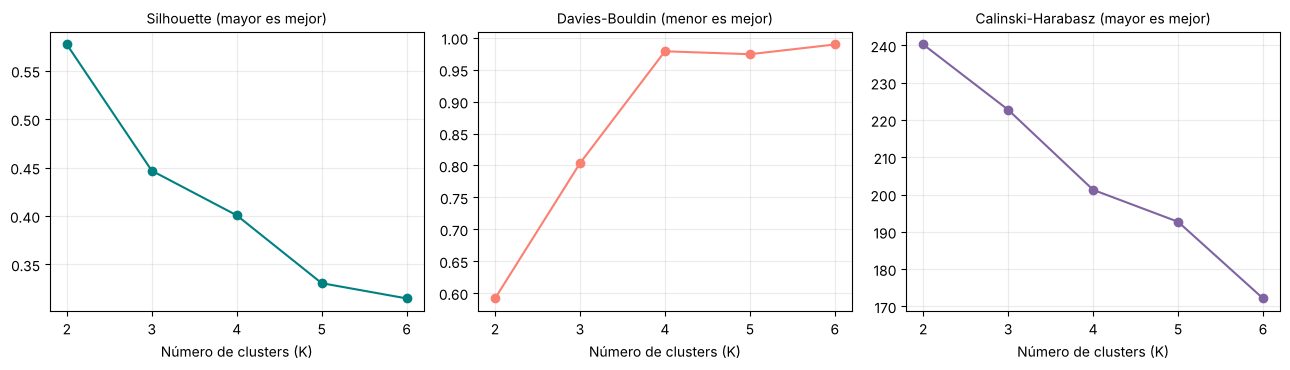

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, color, flecha in zip(axes, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                                   ["teal", "salmon", "#8064A2"], ["mayor es mejor", "menor es mejor", "mayor es mejor"]):
    ax.plot(tabla_jer.index, tabla_jer[col], "o-", color=color)
    ax.set_title(f"{col} ({flecha})", fontsize=10)
    ax.set_xlabel("Número de clusters (K)")
    ax.set_xticks(tabla_jer.index)
plt.tight_layout()
guardar_figura("ej3_metricas_por_k")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 3.4:</font>**

- **Corte propuesto: altura ≈ 20, es decir, K = 2.** Es el corte con el salto más amplio del dendrograma (14,61) y los **tres criterios internos coinciden**: K=2 tiene el mayor Silhouette (0,577), el menor Davies-Bouldin (0,592) y el mayor Calinski-Harabasz (240,2), mejores que en cualquier K mayor.
- **Alternativa:** el corte a altura ≈ 10 (K = 3) corresponde al segundo salto del dendrograma. Sus métricas son peores (Silhouette 0,447; Davies-Bouldin 0,803; Calinski-Harabasz 222,7), por lo que se evalúa como **análisis de sensibilidad** en la sección 3.7 en lugar de elegirlo como modelo principal.
- **Honestidad metodológica:** la elección de K=2 se basa **solo en criterios no supervisados**. Que Iris tenga 3 especies es un conocimiento externo que no debe guiar la decisión; en la sección 3.7 se verá qué ocurre con él.

### <font color="2ECC71">3.5 Agglomerative Clustering con K = 2 y métricas (actividades 8 y 9)

In [33]:
K_JER = 2
agg = AgglomerativeClustering(n_clusters=K_JER, linkage="ward")
etiq_iris = reordenar_etiquetas(agg.fit_predict(Xs_iris), X_iris["petal length (cm)"], ascendente=True)  # 0 = pétalos más cortos

m_iris = metricas_internas(Xs_iris, etiq_iris)
print("Tamaño de cada cluster:", np.bincount(etiq_iris))
pd.DataFrame([m_iris], index=["Jerárquico Ward (K=2)"]).round(4)

Tamaño de cada cluster: [ 49 101]


,Silhouette,Davies-Bouldin,Calinski-Harabasz
Jerárquico Ward (K=2),0.577,0.5917,240.2457


In [34]:
# Perfil de cada cluster en unidades originales (cm)
perfil_iris = X_iris.groupby(etiq_iris).mean().T
perfil_iris.columns = [f"Cluster {c}" for c in perfil_iris.columns]
perfil_iris.round(2)

,Cluster 0,Cluster 1
sepal length (cm),5.02,6.24
sepal width (cm),3.45,2.87
petal length (cm),1.47,4.87
petal width (cm),0.24,1.66


**<font color="2ECC71">Interpretación del Ejercicio 3.5:</font>** Con K=2 se obtienen un cluster de **49 flores** (pétalos muy pequeños: largo 1,47 cm, ancho 0,24 cm, sépalo más ancho) y uno de **101 flores** (pétalo de 4,87 × 1,66 cm de media). Las métricas son **Silhouette = 0,577, Davies-Bouldin = 0,592 y Calinski-Harabasz = 240,2**, valores que indican una separación nítida, en parte porque uno de los clusters está claramente aislado del resto.

### <font color="2ECC71">3.6 Visualización 2D con PCA (actividades 10 y 11)

Varianza explicada: PC1 = 73.0% | PC2 = 22.9% | total = 95.8%


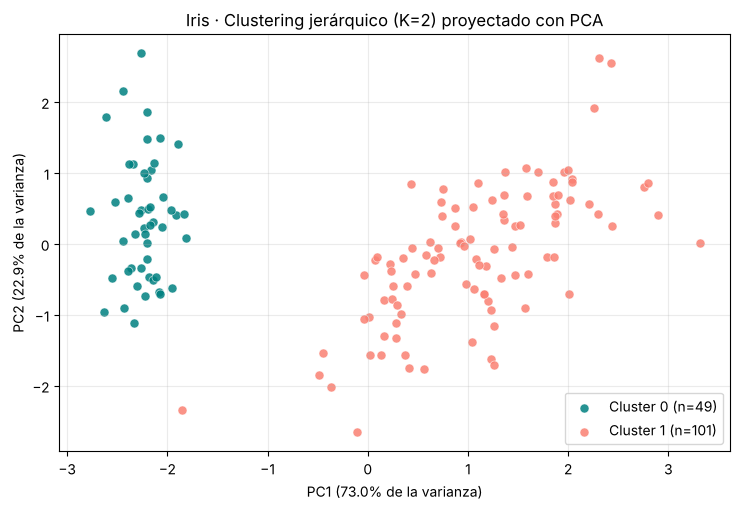

In [35]:
from sklearn.decomposition import PCA

pca_iris = PCA(n_components=2, random_state=SEED)
Z_iris = pca_iris.fit_transform(Xs_iris)
var_iris = pca_iris.explained_variance_ratio_
print(f"Varianza explicada: PC1 = {var_iris[0]:.1%} | PC2 = {var_iris[1]:.1%} | total = {var_iris.sum():.1%}")

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for c in range(K_JER):
    sel = etiq_iris == c
    ax.scatter(Z_iris[sel, 0], Z_iris[sel, 1], s=42, color=COLORES[c], alpha=0.85,
               edgecolor="white", linewidth=0.4, label=f"Cluster {c} (n={sel.sum()})")
ax.set_xlabel(f"PC1 ({var_iris[0]:.1%} de la varianza)")
ax.set_ylabel(f"PC2 ({var_iris[1]:.1%} de la varianza)")
ax.set_title("Iris · Clustering jerárquico (K=2) proyectado con PCA")
ax.legend()
plt.tight_layout()
guardar_figura("ej3_jerarquico_pca")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 3.6:</font>** PCA conserva el **95,8 %** de la varianza (72,96 % + 22,85 %), por lo que el plano 2D es una representación muy fiel. Los dos clusters están **claramente separados** a lo largo de PC1, con un espacio vacío entre ellos. El cluster más grande (101 flores) tiene más dispersión interna y aloja al mismo tiempo a dos subgrupos que se tocan (ver siguiente sección). El punto aislado del cluster 1 que aparece cerca del cluster 0 es la **observación 41**, una *setosa* atípica (ancho de sépalo de 2,3 cm frente a una media de 3,43 cm en su especie) que el método asigna al grupo grande.

### <font color="2ECC71">3.7 Análisis de sensibilidad: K = 3 y comparación con K-Means

>**<font color="BDC3C7">Nota:</font>** Se evalúa el segundo corte del dendrograma (K=3) y se compara con K-Means (K=3) sobre los mismos datos. La especie real se usa **solo para describir** lo que ocurre, no para decidir.

In [36]:
from sklearn.cluster import KMeans

lab_j3 = reordenar_etiquetas(AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xs_iris),
                             X_iris["petal length (cm)"], ascendente=True)
lab_km3 = reordenar_etiquetas(KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(Xs_iris),
                              X_iris["petal length (cm)"], ascendente=True)

modelos_iris = {
    "Jerárquico Ward (K=2) · seleccionado": etiq_iris,
    "Jerárquico Ward (K=3)":                lab_j3,
    "K-Means (K=3)":                        lab_km3,
}
filas = {}
for nombre, lab in modelos_iris.items():
    filas[nombre] = {**metricas_internas(Xs_iris, lab), "ARI (ref.)": adjusted_rand_score(y_iris, lab)}
comp_iris = pd.DataFrame(filas).T
comp_iris.round(4)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (ref.)
Jerárquico Ward (K=2) · seleccionado,0.5770,0.5917,240.2457,0.5438
Jerárquico Ward (K=3),0.4467,0.8035,222.7192,0.6153
K-Means (K=3),0.4599,0.8336,241.9044,0.6201


Jerárquico K=2
Especie real  setosa  versicolor  virginica
Cluster                                    
0                 49           0          0
1                  1          50         50 

Jerárquico K=3
Especie real  setosa  versicolor  virginica
Cluster                                    
0                 49           0          0
1                  1          27          2
2                  0          23         48 



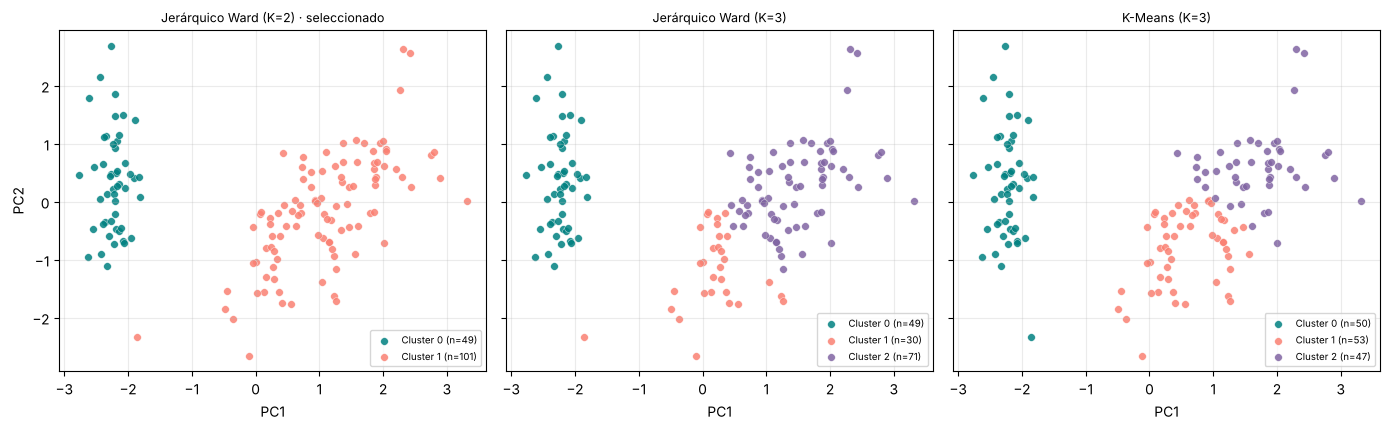

In [37]:
# Cómo se reparten las especies reales en los clusters de K=2 y K=3 (solo referencia)
especies = dict(enumerate(data_iris.target_names))
for nombre, lab in [("Jerárquico K=2", etiq_iris), ("Jerárquico K=3", lab_j3)]:
    print(nombre)
    print(pd.crosstab(pd.Series(lab, name="Cluster"), pd.Series(y_iris.map(especies), name="Especie real")).to_string(), "\n")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, (nombre, lab) in zip(axes, modelos_iris.items()):
    for c in sorted(np.unique(lab)):
        sel = lab == c
        ax.scatter(Z_iris[sel, 0], Z_iris[sel, 1], s=30, color=COLORES[c], alpha=0.85,
                   edgecolor="white", linewidth=0.3, label=f"Cluster {c} (n={sel.sum()})")
    ax.set_title(nombre, fontsize=9)
    ax.set_xlabel("PC1")
    ax.legend(fontsize=7)
axes[0].set_ylabel("PC2")
plt.tight_layout()
guardar_figura("ej3_sensibilidad_k3")
plt.show()

**<font color="2ECC71">Interpretación del Ejercicio 3.7:</font>**

- **K=2 frente a K=3:** con K=3 el cluster grande se divide en dos (71 y 30 flores); el cluster de 49 flores de pétalos pequeños se mantiene. Las métricas internas empeoran (Silhouette 0,577 → 0,447) porque los dos subgrupos nuevos **se tocan**: no hay un hueco entre ellos.
- **Referencia con la especie real (opcional):** K=2 junta *versicolor* y *virginica* en un solo cluster (ARI = 0,544); K=3 las separa en gran medida (ARI = 0,615), aunque con mezcla: el cluster de 71 flores contiene 48 *virginica* y 23 *versicolor*. Es decir, **una métrica interna favorece K=2 y el conocimiento externo favorece K=3**; ambas lecturas son válidas y responden preguntas distintas (separación geométrica frente a taxonomía).
- **Jerárquico frente a K-Means (K=3):** resultados casi idénticos (Silhouette 0,447 frente a 0,460; ARI 0,615 frente a 0,620). La diferencia de fondo no está en la calidad, sino en el procedimiento (ver preguntas de análisis).

---

### <font color="2ECC71">3.8 Preguntas de análisis del Ejercicio 3

>**<font color="BDC3C7">1. ¿Qué información proporciona el dendrograma?:</font>**
Muestra **cómo se fusionan los grupos paso a paso** y a qué distancia lo hacen. Revela la jerarquía completa (qué observaciones se parecen más), permite ver **cuántos grupos hay a cada nivel de detalle** y, mediante los saltos de altura, sugiere un número natural de clusters.

>**<font color="BDC3C7">2. ¿En qué punto realizaría el corte?:</font>**
**A una altura ≈ 20** (cualquier valor entre 12,64 y 27,25 da el mismo resultado), porque ahí está el salto más grande del dendrograma (14,61).

>**<font color="BDC3C7">3. ¿Cuántos clusters propone y por qué?:</font>**
**2 clusters.** Lo respaldan el salto de altura y los tres criterios internos (Silhouette 0,577, Davies-Bouldin 0,592, Calinski-Harabasz 240,2). Como alternativa, K=3 (corte ≈ 10) es defendible si se busca más detalle, pero sus métricas son peores.

>**<font color="BDC3C7">4. ¿Qué tan separados se encuentran los grupos?:</font>**
Con K=2 la separación es **clara** (Silhouette 0,577; hueco visible en PCA, que explica 95,8 % de la varianza). Con K=3, los dos grupos que provienen del cluster grande **se solapan** en la frontera (Silhouette 0,447).

>**<font color="BDC3C7">5. ¿Qué diferencias encuentra entre este procedimiento y K-Means?:</font>**
El jerárquico **no necesita fijar K de antemano** (se decide al cortar el árbol), es **determinista** (sin inicialización aleatoria) y entrega **todas las soluciones anidadas** a la vez; K-Means requiere K, depende de la inicialización (se mitiga con `n_init`) y es mucho más **escalable**. En cambio, las fusiones del jerárquico son **irreversibles** y su coste en memoria y tiempo crece al menos de forma cuadrática con n. Con K=3 ambos dieron resultados muy parecidos en Iris.

>**<font color="BDC3C7">6. ¿Qué ventajas ofrece una representación jerárquica?:</font>**
Permite **explorar la estructura a varios niveles**, comunicar visualmente las relaciones entre observaciones, elegir K con evidencia en lugar de suponerlo y obtener **sub-grupos dentro de grupos** (taxonomías). Es muy útil en análisis exploratorio con conjuntos pequeños o medianos.

---

<a id="seccion-4"></a>
##**<font color="BB86FC">Sección 4 · Comparación de los algoritmos**

>**<font color="BDC3C7">Advertencia metodológica:</font>** cada algoritmo se aplicó a un **dataset distinto** (Wine, Make Moons, Iris), así que los valores de Silhouette, Davies-Bouldin y Calinski-Harabasz **no son comparables entre columnas** como si midieran qué algoritmo es "mejor". Describen qué tan bien separó cada algoritmo **su** problema. Por eso la tabla se acompaña de las comparaciones sobre el mismo dato hechas en las secciones 2.7 (DBSCAN frente a K-Means en Moons) y 3.7 (jerárquico frente a K-Means en Iris).

---

### <font color="2ECC71">4.1 Tabla comparativa

In [38]:
pd.set_option("display.max_colwidth", None)

# Métricas de cada algoritmo en SU dataset (valores calculados en las secciones anteriores)
m_db = metricas_internas(Xs_moons, lab_db)

def fmt(x, d=3):
    """Formatea un número con d decimales."""
    return f"{x:.{d}f}"

tabla_comp = pd.DataFrame({
    "K-Means (Wine)": [
        "Asigna cada punto al centroide más cercano y recalcula los centroides hasta converger",
        "3 (elegido con codo + Silhouette)",
        "K, n_init, init (distancia euclidiana)",
        fmt(m_wine["Silhouette"]), fmt(m_wine["Davies-Bouldin"]), fmt(m_wine["Calinski-Harabasz"], 1),
        "No (todo punto se asigna a un cluster)",
        "Sí",
        "Rápido y escalable; simple de interpretar con centroides",
        "Supone clusters convexos y de tamaño similar; sensible a escala y a la inicialización",
    ],
    "DBSCAN (Moons)": [
        "Une puntos densamente conectados (vecindad eps con al menos min_samples puntos)",
        "2 (más 0 puntos de ruido con la configuración elegida)",
        "eps, min_samples (distancia)",
        fmt(m_db["Silhouette"]), fmt(m_db["Davies-Bouldin"]), fmt(m_db["Calinski-Harabasz"], 1),
        "Sí (etiqueta -1; con eps=0,20 detecta 4 puntos)",
        "No",
        "Forma arbitraria de clusters y detección de ruido",
        "Muy sensible a eps; falla con densidades distintas y en alta dimensión",
    ],
    "Clustering Jerárquico (Iris)": [
        "Fusiona de forma sucesiva los dos grupos más cercanos (Ward) y se corta el dendrograma",
        "2 (corte a altura ≈ 20)",
        "n_clusters o umbral de distancia, linkage (Ward), métrica",
        fmt(m_iris["Silhouette"]), fmt(m_iris["Davies-Bouldin"]), fmt(m_iris["Calinski-Harabasz"], 1),
        "No",
        "No para construir el árbol; se decide al cortarlo",
        "Dendrograma: estructura a varios niveles, determinista",
        "Coste O(n²) en memoria; fusiones irreversibles; poco escalable",
    ],
}, index=["Forma de construir los grupos", "Número de clusters obtenidos", "Hiperparámetros principales",
          "Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Score", "Identifica ruido",
          "Requiere definir previamente el número de clusters", "Principal ventaja", "Principal limitación"])
tabla_comp.index.name = "Aspecto"
tabla_comp

,K-Means (Wine),DBSCAN (Moons),Clustering Jerárquico (Iris)
Aspecto,,,
Forma de construir los grupos,Asigna cada punto al centroide más cercano y recalcula los centroides hasta converger,Une puntos densamente conectados (vecindad eps con al menos min_samples puntos),Fusiona de forma sucesiva los dos grupos más cercanos (Ward) y se corta el dendrograma
Número de clusters obtenidos,3 (elegido con codo + Silhouette),2 (más 0 puntos de ruido con la configuración elegida),2 (corte a altura ≈ 20)
Hiperparámetros principales,"K, n_init, init (distancia euclidiana)","eps, min_samples (distancia)","n_clusters o umbral de distancia, linkage (Ward), métrica"
Silhouette Score,0.285,0.386,0.577
Davies-Bouldin Index,1.389,1.022,0.592
Calinski-Harabasz Score,70.9,433.9,240.2
Identifica ruido,No (todo punto se asigna a un cluster),"Sí (etiqueta -1; con eps=0,20 detecta 4 puntos)",No
Requiere definir previamente el número de clusters,Sí,No,No para construir el árbol; se decide al cortarlo
Principal ventaja,Rápido y escalable; simple de interpretar con centroides,Forma arbitraria de clusters y detección de ruido,"Dendrograma: estructura a varios niveles, determinista"


In [39]:
# Contraste sobre EL MISMO dato (únicamente referencia): ¿qué tan bien recupera cada algoritmo la estructura real?
ref = pd.DataFrame({
    "Dataset": ["Wine", "Moons", "Moons", "Iris", "Iris"],
    "Algoritmo": ["K-Means (K=3)", "DBSCAN (0.30, 5)", "K-Means (K=2)", "Jerárquico (K=3)", "K-Means (K=3)"],
    "ARI (ref.)": [adjusted_rand_score(y_wine, etiq_wine), adjusted_rand_score(y_moons, lab_db),
                   adjusted_rand_score(y_moons, lab_km_moons), adjusted_rand_score(y_iris, lab_j3),
                   adjusted_rand_score(y_iris, lab_km3)],
})
ref.round(3)

,Dataset,Algoritmo,ARI (ref.)
0,Wine,K-Means (K=3),0.897
1,Moons,"DBSCAN (0.30, 5)",1.000
2,Moons,K-Means (K=2),0.445
3,Iris,Jerárquico (K=3),0.615
4,Iris,K-Means (K=3),0.620


**<font color="2ECC71">Interpretación de la Sección 4:</font>**

- **Quién necesita qué:** solo K-Means exige fijar K antes de ejecutar; DBSCAN lo descubre a partir de la densidad y el jerárquico lo deja para después de construir el árbol.
- **Métricas internas y forma de los clusters:** las métricas de este ejercicio **premian clusters compactos y redondeados**. Por eso en Moons K-Means obtuvo mejores valores que DBSCAN (Silhouette 0,494 frente a 0,386) aun cuando su agrupamiento era incorrecto (ARI 0,445 frente a 1,000). Ninguna métrica interna sustituye la inspección visual y el conocimiento del problema.
- **Ruido:** solo DBSCAN lo separa explícitamente; en K-Means y en el jerárquico los atípicos terminan dentro de algún cluster y pueden distorsionar centroides y fusiones.

---

### <font color="2ECC71">4.2 Pregunta final: ¿en qué tipo de problema utilizaría cada algoritmo y por qué?

>**<font color="BDC3C7">K-Means:</font>**
Para **segmentar grandes volúmenes de datos numéricos** cuando se espera que los grupos sean aproximadamente esféricos y de tamaño parecido y se puede estimar K: por ejemplo, segmentación de clientes por comportamiento de compra, cuantización de colores en imágenes o agrupación de productos. Se elige por su **velocidad y escalabilidad** y porque los centroides son fáciles de explicar al negocio (como los perfiles del cluster 0, 1 y 2 de Wine). Requiere estandarizar las variables.

>**<font color="BDC3C7">DBSCAN:</font>**
Para datos con **formas irregulares o con ruido y atípicos** y donde no se conoce el número de grupos: datos geoespaciales (zonas de alta concentración de incidentes, paradas o sensores), **detección de anomalías** o fraude (los puntos -1 son candidatos a revisión) y datos de trayectorias. Se elige porque **encuentra formas arbitrarias** (como las lunas) y **separa el ruido**. Funciona mejor en pocas dimensiones y con densidades similares.

>**<font color="BDC3C7">Clustering jerárquico:</font>**
Para conjuntos **pequeños o medianos** donde interesa la **estructura a varios niveles** o una taxonomía: genómica y filogenia, agrupación de documentos o especies, análisis exploratorio para decidir cuántos segmentos considerar. Se elige porque el **dendrograma** permite justificar K con evidencia, no requiere inicialización aleatoria y muestra relaciones entre grupos. No es apropiado para decenas de miles de observaciones por su coste cuadrático.

---

<a id="seccion-5"></a>
##**<font color="BB86FC">Sección 5 · Conclusiones**

<font color=#FFFFFF>

1. **K-Means (Wine):** con datos estandarizados, el codo, el Silhouette, Davies-Bouldin y Calinski-Harabasz coinciden en **K = 3**. El modelo es estable (misma solución con cinco semillas) pero la estructura es **moderada** (Silhouette 0,285; Davies-Bouldin 1,389; Calinski-Harabasz 70,94). Los clusters se distinguen por flavonoides, fenoles, prolina, color y alcohol y coinciden en 172 de 178 muestras con los cultivares reales (ARI 0,897), que no se usaron para agrupar.
2. **El preprocesamiento cambia el resultado:** sin estandarizar, el Silhouette sube a 0,571 pero el ARI cae de 0,897 a 0,371. **Una métrica interna alta no implica clusters útiles.**
3. **DBSCAN (Moons):** `eps = 0,30` y `min_samples = 5` recuperan exactamente las dos lunas (2 clusters de 250 puntos, 0 % de ruido). El rango útil de `eps` es acotado (0,25 a 0,40 en las pruebas): con valores de 0,15 o menos la solución se fragmenta o se vuelve ruido, y con 0,50 las lunas se fusionan.
4. **Las métricas internas favorecen formas convexas:** K-Means obtuvo mejor Silhouette que DBSCAN en Moons (0,494 frente a 0,386) siendo un resultado incorrecto. Además, el **ruido** debe excluirse del cálculo y **reportarse siempre su porcentaje**.
5. **Jerárquico (Iris):** el dendrograma tiene un salto dominante (14,61) y los tres criterios internos apuntan a **K = 2** (Silhouette 0,577). K=3 es una alternativa defendible desde el conocimiento externo (ARI 0,615), con métricas internas peores. Su resultado es casi idéntico al de K-Means con K=3.
6. **Recomendación general:** elegir el algoritmo según la **forma esperada de los grupos, la presencia de ruido y el tamaño de los datos**, no según la métrica más alta; validar con **varios criterios** y siempre con visualización.
7. **Limitaciones:** los datasets son pequeños y estándar; las métricas no son comparables entre datasets distintos; PCA solo conserva el 55,4 % de la varianza en Wine; no se exploraron otras distancias, enlaces ni algoritmos (p. ej. Gaussian Mixture u OPTICS); y no se evaluó la estabilidad de DBSCAN y del jerárquico frente a remuestreo.

---
<a id="seccion-6"></a>
##**<font color="BB86FC">Sección 6 · Referencias**

- Calinski, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1-27. https://doi.org/10.1080/03610927408827101
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224-227. https://doi.org/10.1109/TPAMI.1979.4766909
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)* (pp. 226-231). AAAI Press.
- Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of Eugenics, 7*(2), 179-188. https://doi.org/10.1111/j.1469-1809.1936.tb02137.x
- Forina, M., Aeberhard, S., & Leardi, R. (1991). *Wine* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193-218. https://doi.org/10.1007/BF01908075
- Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley. https://doi.org/10.1002/9780470316801
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. En L. M. Le Cam & J. Neyman (Eds.), *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability* (Vol. 1, pp. 281-297). University of California Press.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65. https://doi.org/10.1016/0377-0427(87)90125-7
- Scikit-learn. *Clustering*. https://scikit-learn.org/stable/modules/clustering.html
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236-244. https://doi.org/10.1080/01621459.1963.10500845
- Universidad de Cundinamarca · CADI Introducción a Machine Learning (2026). *Ejercicios propuestos - Clustering (Semana 11)*.